In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

Empty Can:
   Peak Amplitude: 396.0 mV at 312 Hz
   90° Phase Frequency: 312.00 Hz
----------------------------------------
50ml Filled Can:
   Peak Amplitude: 550.0 mV at 339 Hz
   90° Phase Frequency: 337.33 Hz


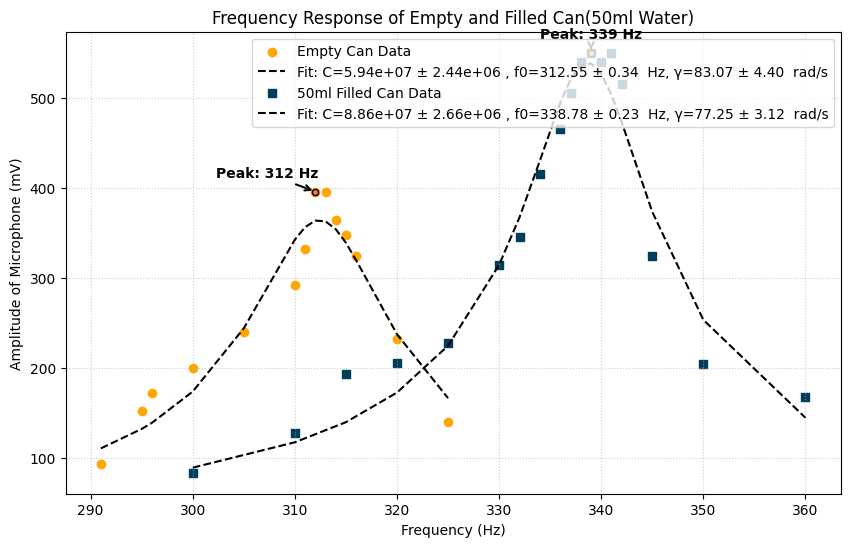

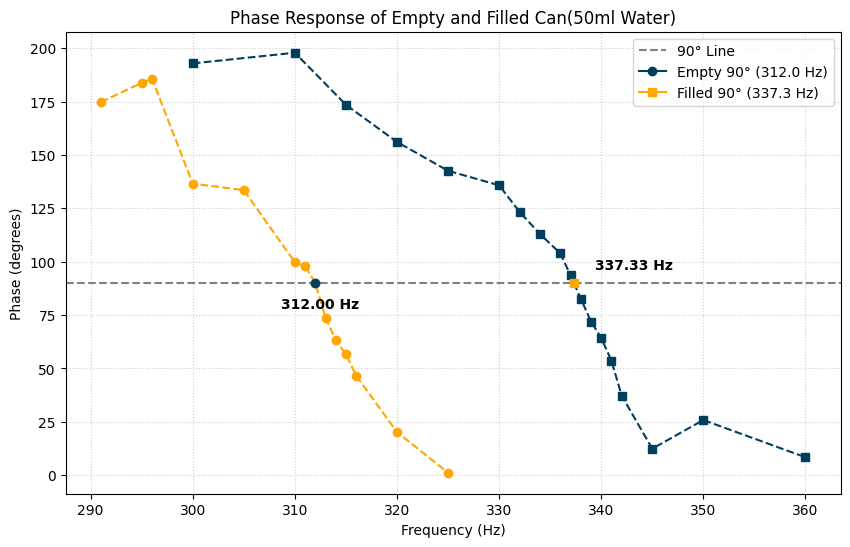

In [74]:

# Data
# Empty Can
f1 = np.array([291, 295, 296, 300, 305, 310, 311, 312, 313, 314, 315, 316, 320, 325])
A1 = np.array([93.6, 152, 172, 200, 240, 292, 332, 396, 396, 364, 348, 324, 232, 140])
p1 = np.array([174.8, 183.8, 185.8, 136.6, 133.5, 99.75, 97.98, 90, 73.8, 63.3, 56.69, 46.64, 20.19, 1.169])
# 50ml Filled Can
f2 = np.array([300, 310, 315, 320, 325, 330, 332, 334, 336, 337, 338, 339, 340, 341, 342, 345, 350, 360])
A2 = np.array([33.6, 51.2, 77.6, 82.4, 91.2, 126, 138, 166, 186, 202, 216, 220, 216, 220, 206, 130, 82, 67.2])
A2 = 2.5*A2 # gain of amplifier is reduced to 2.5 times for the filled can data
p2_c = np.array([192.9, 197.9, 173.5, 156.1, 142.6, 135.8, 123.4, 113, 103.9, 93.6, 82.7, 72, 64.3, 53.7, 37.3, 12.41, 25.85, 8.417])

# --- Calculations ---

# Peak Amplitudes (finds maximum, taking the first peak if tied)
idx_amp_peak1 = np.argmax(A1)
f_amp_peak1, A_peak1 = f1[idx_amp_peak1], A1[idx_amp_peak1]

idx_amp_peak2 = np.argmax(A2)
f_amp_peak2, A_peak2 = f2[idx_amp_peak2], A2[idx_amp_peak2]

# Exact Frequency at 90 degrees Phase (Interpolation for accuracy)
f_phase_90_can1 = np.interp(90, p1[::-1], f1[::-1])
f_phase_90_can2 = np.interp(90, p2_c[::-1], f2[::-1])

# --- Print Summary Data ---
print(f"Empty Can:")
print(f"   Peak Amplitude: {A_peak1:.1f} mV at {f_amp_peak1} Hz")
print(f"   90° Phase Frequency: {f_phase_90_can1:.2f} Hz")
print("-" * 40)
print(f"50ml Filled Can:")
print(f"   Peak Amplitude: {A_peak2:.1f} mV at {f_amp_peak2} Hz")
print(f"   90° Phase Frequency: {f_phase_90_can2:.2f} Hz")


# fitting
# Single damped harmonic oscillator
def amplitude_model(f_hz, C, f0_hz, gamma):
    omega = 2 * np.pi * f_hz
    omega0 = 2 * np.pi * f0_hz

    return C / np.sqrt(
        (omega0**2 - omega**2)**2 + (gamma * omega)**2
    )

# Initial guesses: scale, resonance frequency, damping
p0 = [1e8, f1[np.argmax(A1)], 100.0]

# Weighted nonlinear least-squares fit
popt, pcov = curve_fit(
    amplitude_model,
    f1,
    A1,
    p0=p0,
    sigma=np.sqrt(A1),  # Assuming Poisson noise for amplitude measurements
    absolute_sigma=True,
    bounds=([0, 0, 0], [np.inf, np.inf, np.inf]),
    maxfev=50000
)
# for 50ml fitting
popt1, pcov1 = curve_fit(
    amplitude_model,
    f2,
    A2,
    p0=p0,
    sigma=np.sqrt(A2),  # Assuming Poisson noise for amplitude measurements
    absolute_sigma=True,
    bounds=([0, 0, 0], [np.inf, np.inf, np.inf]),
    maxfev=50000
)
# fit equations for both empty and filled can with errors
fit_eq1 = f"Fit: C={popt[0]:.2e} ± {np.sqrt(pcov[0, 0]):.2e} , f0={popt[1]:.2f} ± {np.sqrt(pcov[1, 1]):.2f}  Hz, γ={popt[2]:.2f} ± {np.sqrt(pcov[2, 2]):.2f}  rad/s"
fit_eq2 = f"Fit: C={popt1[0]:.2e} ± {np.sqrt(pcov1[0, 0]):.2e} , f0={popt1[1]:.2f} ± {np.sqrt(pcov1[1, 1]):.2f}  Hz, γ={popt1[2]:.2f} ± {np.sqrt(pcov1[2, 2]):.2f}  rad/s"
# --- Plot 1: Amplitude Response ---
plt.figure(figsize=(10, 6))
plt.scatter(f1, A1, label='Empty Can Data', marker='o', color='#ffa600')
# Mark Peaks
plt.scatter( f_amp_peak1, A_peak1, color='#FF6F61', edgecolor='black', s=20, zorder=5)
# Annotations
plt.annotate(f'Peak: {f_amp_peak1} Hz', (f_amp_peak1, A_peak1), textcoords="offset points", xytext=(-35,10), ha='center', fontweight='bold', color="#050404",arrowprops=dict(
        arrowstyle='->',color="#0E0A0A",lw=1.5))
plt.plot(f1, amplitude_model(f1, *popt), '--', color="#000000", label=fit_eq1) # for empty can fit
plt.scatter(f2, A2, label='50ml Filled Can Data', marker='s', color='#003f5c')
plt.scatter( f_amp_peak2, A_peak2, color='#ffa600', edgecolor='black', s=20, zorder=5)
plt.annotate(f'Peak: {f_amp_peak2} Hz', (f_amp_peak2, A_peak2), textcoords="offset points", xytext=(0,10), ha='center', fontweight='bold',color = "#050404",arrowprops=dict(
        arrowstyle='->',color="#0E0A0A",lw=1.5))
plt.plot(f2, amplitude_model(f2, *popt1), '--', color="#000000", label=fit_eq2) # for filled can fit

plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude of Microphone (mV)')
plt.title('Frequency Response of Empty and Filled Can(50ml Water)')
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# --- Plot 2: Phase Response ---
plt.figure(figsize=(10, 6))
plt.plot(f1, p1, marker='o',linestyle='--', color='#ffa600')
plt.plot(f2, p2_c, marker='s',linestyle='--', color='#003f5c')

plt.axhline(y=90, color='gray', linestyle='--', label='90° Line')

# Mark 90 Degree Points
plt.plot(f_phase_90_can1, 90, marker='o',color='#003f5c', label=f'Empty 90° ({f_phase_90_can1:.1f} Hz)')
plt.plot(f_phase_90_can2, 90, marker='s', color='#ffa600', label=f'Filled 90° ({f_phase_90_can2:.1f} Hz)')

# Annotations
plt.annotate(f'{f_phase_90_can1:.2f} Hz', (f_phase_90_can1, 90), textcoords="offset points", xytext=(-25,-18), fontweight='bold', color='black')
plt.annotate(f'{f_phase_90_can2:.2f} Hz', (f_phase_90_can2, 90), textcoords="offset points", xytext=(15,10), fontweight='bold', color='black')

# plt.axvline(x=f_phase_90_can1, color='red', linestyle=':', alpha=0.6)
# plt.axvline(x=f_phase_90_can2, color='green', linestyle=':', alpha=0.6)

plt.xlabel('Frequency (Hz)')
plt.ylabel('Phase (degrees)')
plt.title('Phase Response of Empty and Filled Can(50ml Water)')
plt.legend(loc='upper right') # put top right out of plot
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

slope k = 6.624 +/- 0.035 Hz per m^-3/2,  R^2 = 0.9937,  rms residual = 5.8 Hz


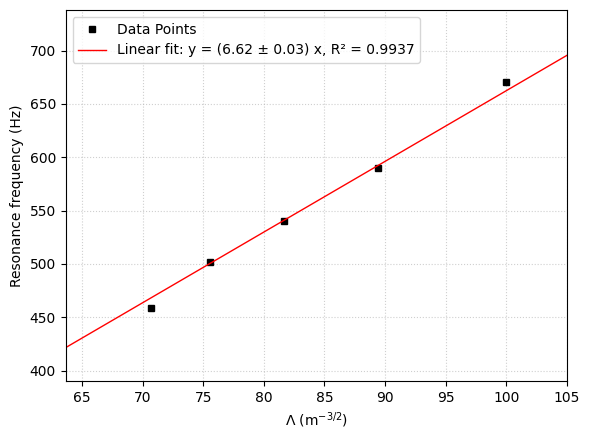

In [69]:
"""
Resonance frequency vs air volume (reproduces Fig. 1(b) of Wilkinson et al.).
Helmholtz resonator: f0 = k * Lambda, with Lambda = 1/sqrt(V0)  ->  straight line through the origin.
"""

# ---- data ----
V_CAN_ML   = 200.0                                  # internal volume of the empty can (ml)
V_water_ml = np.array([0, 25, 50, 75, 100])         # water added (ml)
f_hz       = np.array([459, 502, 540, 590, 671])    # resonance frequency (Hz)
A = np.array([1.16, 1.04, 0.776, 0.616, 0.52])  # Peak amplitudes in mV
phase = np.array([72,47 , 18.49, -18.56, -28.44])  # Phase in degrees

# ---- Lambda = 1/sqrt(V0), with V0 = air volume in m^3 ----
Lam = 1.0 / np.sqrt((V_CAN_ML - V_water_ml) * 1e-6)  # m^-3/2

# ---- linear fit through the origin: f0 = k * Lambda ----
(k,), pcov = curve_fit(lambda x, k: k * x, Lam, f_hz)
k_err = np.sqrt(pcov[0, 0])
resid = f_hz - k * Lam
r2 = 1 - np.sum(resid**2) / np.sum((f_hz - f_hz.mean())**2)
print(f"slope k = {k:.3f} +/- {k_err:.3f} Hz per m^-3/2,  R^2 = {r2:.4f},  "
      f"rms residual = {np.sqrt(np.mean(resid**2)):.1f} Hz")

# ---- plot ----
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(Lam, f_hz, "ks", ms=5, label="Data Points")
xx = np.linspace(0, Lam.max() * 1.05, 100)
ax.plot(xx, k * xx, "r-", lw=1, label=f"Linear fit: y = ({k:.2f} ± {k_err:.2f}) x, R² = {r2:.4f}")
ax.set_xlim(Lam.min() * 0.9, Lam.max() * 1.05)
ax.set_ylim(f_hz.min() * 0.85, f_hz.max() * 1.1)
ax.set_xlabel(r"$\Lambda$ (m$^{-3/2}$)")
ax.set_ylabel("Resonance frequency (Hz)")
ax.grid(ls=":", alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()